# CS-317: Reinforcement Learning — Lab 4
## Solving Markov Decision Processes with Dynamic Programming
### **Muhammad Sikandar Hussain**

This notebook provides the warehouse environment and a few helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

Do not use any reinforcement-learning library (e.g. `gymnasium`, `stable-baselines3`). NumPy and Matplotlib only.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng_global = np.random.default_rng(42)
np.set_printoptions(precision=3, suppress=True)


---
## Provided Starter Code

Run the cells in this section as-is. You do not need to modify them, but you should read through `build_mdp` carefully — you will need to understand the state indexing and the layout of `P` and `R` for every task below.


In [2]:
# ---------------------------------------------------------------
# Warehouse layout
#
#   S  .  .  .
#   .  #  .  F
#   .  .  ~  .
#   .  .  .  G
#
#   S = start        G = delivery (terminal, +goal)
#   # = shelf (blocked)     F = forklift zone (terminal, +forklift)
#   ~ = wet floor (higher slip probability)
#
# Cells are indexed (row, col), (0,0) at the top-left.
# ---------------------------------------------------------------

LAYOUT = ["S...",
          ".#.F",
          "..~.",
          "...G"]

ACTIONS = ["Up", "Down", "Left", "Right"]     # action index 0,1,2,3
_DIRS = [(-1, 0), (1, 0), (0, -1), (0, 1)]    # matches ACTIONS order
_PERP = {0: [2, 3], 1: [2, 3], 2: [0, 1], 3: [0, 1]}  # perpendicular actions


def build_mdp(p=0.8, p_wet=0.6, step=-1.0, goal=50.0, forklift=-20.0, bump=-5.0,
              layout=LAYOUT):
    """Builds the tabular MDP for the warehouse grid.

    Returns
    -------
    P : ndarray, shape (S, A, S)
        P[s, a, s2] = probability of transitioning from state s to state s2
        under action a.
    R : ndarray, shape (S, A, S)
        R[s, a, s2] = reward received on that transition.
    state_index : dict[(row, col) -> int]
        Maps free grid cells to their state index. The goal and forklift
        cells are NOT included here — entering them sends the robot
        directly to the terminal state.
    terminal_id : int
        Index of the absorbing terminal state (last row/col of P and R).
    """
    n_rows, n_cols = len(layout), len(layout[0])
    free_cells = [(r, c) for r in range(n_rows) for c in range(n_cols)
                  if layout[r][c] not in "#GF"]
    state_index = {rc: i for i, rc in enumerate(free_cells)}
    n_free = len(free_cells)
    terminal_id = n_free                      # one extra absorbing state
    n_states = n_free + 1
    n_actions = len(ACTIONS)

    P = np.zeros((n_states, n_actions, n_states))
    R = np.zeros((n_states, n_actions, n_states))
    P[terminal_id, :, terminal_id] = 1.0       # terminal is absorbing

    for (r, c), s in state_index.items():
        p_intended = p_wet if layout[r][c] == "~" else p
        for a in range(n_actions):
            outcomes = [(a, p_intended)] + [(pa, (1 - p_intended) / 2) for pa in _PERP[a]]
            for direction, prob in outcomes:
                dr, dc = _DIRS[direction]
                nr, nc = r + dr, c + dc
                out_of_bounds = not (0 <= nr < n_rows and 0 <= nc < n_cols)
                if out_of_bounds or layout[nr][nc] == "#":
                    # blocked move: stay in place, pay the bump penalty
                    P[s, a, s] += prob
                    R[s, a, s] = step + bump
                elif layout[nr][nc] == "G":
                    P[s, a, terminal_id] += prob
                    R[s, a, terminal_id] = step + goal
                elif layout[nr][nc] == "F":
                    P[s, a, terminal_id] += prob
                    R[s, a, terminal_id] = step + forklift
                else:
                    s2 = state_index[(nr, nc)]
                    P[s, a, s2] += prob
                    R[s, a, s2] = step

    return P, R, state_index, terminal_id


P, R, state_index, terminal_id = build_mdp()
n_states, n_actions = P.shape[0], P.shape[1]
print(f"n_states = {n_states} (including terminal), n_actions = {n_actions}")
print("state_index:", state_index)


n_states = 14 (including terminal), n_actions = 4
state_index: {(0, 0): 0, (0, 1): 1, (0, 2): 2, (0, 3): 3, (1, 0): 4, (1, 2): 5, (2, 0): 6, (2, 1): 7, (2, 2): 8, (2, 3): 9, (3, 0): 10, (3, 1): 11, (3, 2): 12}


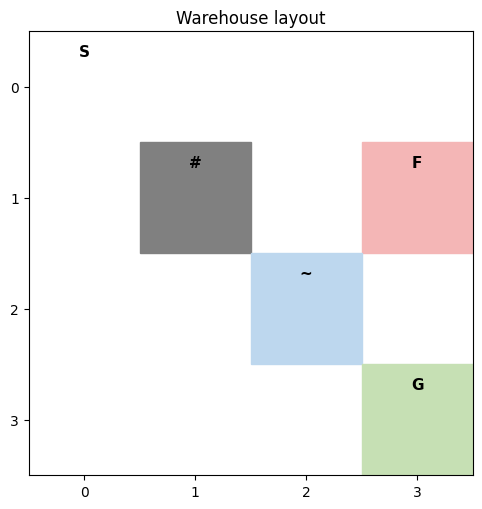

In [3]:
def plot_grid(values=None, policy=None, layout=LAYOUT, state_index=state_index, title=""):
    """Draws the warehouse layout, optionally overlaid with a value heatmap
    and/or policy arrows.

    Parameters
    ----------
    values : ndarray of shape (n_states,), optional
        If given, non-terminal free cells are shaded by their value.
    policy : ndarray of shape (n_states,), optional
        If given, an arrow for the greedy action is drawn in each free cell.
        Expected to contain an action index (0=Up,1=Down,2=Left,3=Right)
        per state, e.g. the output of `Q.argmax(axis=1)`.
    """
    n_rows, n_cols = len(layout), len(layout[0])
    arrow = {0: (0, 0.3), 1: (0, -0.3), 2: (-0.3, 0), 3: (0.3, 0)}
    fig, ax = plt.subplots(figsize=(n_cols * 1.3, n_rows * 1.3))

    grid_vals = np.zeros((n_rows, n_cols))
    if values is not None:
        for (r, c), s in state_index.items():
            grid_vals[r, c] = values[s]

    im = ax.imshow(grid_vals, cmap="YlGn" if values is not None else "Greys",
                    vmin=grid_vals.min() if values is not None else 0,
                    vmax=grid_vals.max() if values is not None else 1, alpha=0.85)

    for r in range(n_rows):
        for c in range(n_cols):
            ch = layout[r][c]
            face = {"#": "0.5", "F": "#f4b6b6", "G": "#c6e0b4", "~": "#bdd7ee"}.get(ch, None)
            if face is not None:
                ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color=face))
            label = "" if ch == "." else ch
            ax.text(c, r - 0.32, label, ha="center", va="center", fontsize=11, fontweight="bold")
            if values is not None and (r, c) in state_index:
                ax.text(c, r, f"{grid_vals[r, c]:.1f}", ha="center", va="center", fontsize=9)
            if policy is not None and (r, c) in state_index:
                s = state_index[(r, c)]
                dx, dy = arrow[int(policy[s])]
                ax.annotate("", xy=(c + dx, r + dy), xytext=(c, r),
                            arrowprops=dict(arrowstyle="->", lw=2, color="crimson"))

    ax.set_xticks(range(n_cols)); ax.set_yticks(range(n_rows))
    ax.set_xlim(-0.5, n_cols - 0.5); ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


plot_grid(title="Warehouse layout")


In [4]:
def rule_based_policy(layout=LAYOUT, state_index=state_index, n_states=n_states, n_actions=n_actions,
                       goal_cell=(3, 3)):
    """The fixed rule from Part 2, Task 2: move one step toward the goal
    along the axis with the larger remaining distance (ties resolved
    vertically). Has no knowledge of the shelf or the forklift zone.

    Returns a deterministic policy as a one-hot array of shape (n_states, n_actions).
    """
    pol = np.zeros((n_states, n_actions))
    for (r, c), s in state_index.items():
        dr, dc = goal_cell[0] - r, goal_cell[1] - c
        if abs(dr) >= abs(dc) and dr != 0:
            a = 1 if dr > 0 else 0          # Down or Up
        elif dc != 0:
            a = 3 if dc > 0 else 2          # Right or Left
        else:
            a = 1
        pol[s, a] = 1.0
    pol[terminal_id, 0] = 1.0               # arbitrary, terminal never acts
    return pol


rule_policy = rule_based_policy()
print("Rule-based action at (0,0):", ACTIONS[rule_policy[state_index[(0,0)]].argmax()])


Rule-based action at (0,0): Down


In [5]:
def simulate(policy, n_episodes=500, max_steps=100, seed=42,
             P=P, R=R, state_index=state_index, terminal_id=terminal_id, gamma=0.95):
    """Rolls out `policy` for `n_episodes` episodes starting from (0,0).

    `policy` may be a stochastic policy of shape (n_states, n_actions)
    (rows summing to 1) or a deterministic action array of shape (n_states,).

    Returns a dict of episode-level arrays: 'return' (discounted),
    'length', 'blocked_moves', and 'outcome' (one of 'goal', 'forklift', 'timeout').
    """
    rng = np.random.default_rng(seed)
    if policy.ndim == 1:
        onehot = np.zeros((policy.shape[0], P.shape[1]))
        onehot[np.arange(policy.shape[0]), policy] = 1.0
        policy = onehot

    start = state_index[(0, 0)]
    results = {"return": [], "length": [], "blocked_moves": [], "outcome": []}

    for _ in range(n_episodes):
        s = start
        G, discount, blocked, outcome = 0.0, 1.0, 0, "timeout"
        for t in range(max_steps):
            a = rng.choice(P.shape[1], p=policy[s])
            s2 = rng.choice(P.shape[2], p=P[s, a])
            r = R[s, a, s2]
            G += discount * r
            discount *= gamma
            if s2 == s and s != terminal_id:
                blocked += 1
            if s2 == terminal_id:
                outcome = "goal" if r > 0 else "forklift"
                s = s2
                break
            s = s2
        results["return"].append(G)
        results["length"].append(t + 1)
        results["blocked_moves"].append(blocked)
        results["outcome"].append(outcome)

    return {k: np.array(v) if k != "outcome" else v for k, v in results.items()}


demo = simulate(rule_policy, n_episodes=20)
print("Demo (rule-based, 20 episodes) mean return:", demo["return"].mean())


Demo (rule-based, 20 episodes) mean return: -24.733635005764224


---
## Part 1: Inspect and Validate the MDP  *(20 min)*

### Task 1: Build and Validate

Using `P` and `R` already built above, implement the checks described in the lab manual.


In [6]:
# 1a: validate every transition-probability row
row_sums = P.sum(axis=2)
print("All P[s,a,:] rows sum to 1:", np.allclose(row_sums, 1.0))
print("No negative transition probabilities:", np.all(P >= 0.0))
print("Maximum row-sum error:", np.max(np.abs(row_sums - 1.0)))

# 1b: validate the absorbing, zero-reward terminal state
terminal_absorbing = (
    np.allclose(P[terminal_id, :, terminal_id], 1.0)
    and np.allclose(np.delete(P[terminal_id], terminal_id, axis=1), 0.0)
)
terminal_zero_reward = np.allclose(R[terminal_id], 0.0)
print("Terminal state is absorbing:", terminal_absorbing)
print("Terminal transitions have zero reward:", terminal_zero_reward)

assert np.allclose(row_sums, 1.0)
assert np.all(P >= 0.0)
assert terminal_absorbing and terminal_zero_reward


All P[s,a,:] rows sum to 1: True
No negative transition probabilities: True
Maximum row-sum error: 0.0
Terminal state is absorbing: True
Terminal transitions have zero reward: True


In [7]:
inv_index = {v: k for k, v in state_index.items()}

def print_outcomes(cell, action_name):
    s, a = state_index[cell], ACTIONS.index(action_name)
    print(f"From {cell}, action {action_name}:")
    for s2 in np.flatnonzero(P[s, a] > 0):
        label = "terminal" if s2 == terminal_id else str(inv_index[s2])
        print(f"  next={label:>8s}, probability={P[s,a,s2]:.3f}, reward={R[s,a,s2]:.1f}")
    expected_reward = np.sum(P[s, a] * R[s, a])
    print(f"  expected immediate reward = {expected_reward:.3f}\n")

for cell, action in [((0, 0), "Right"), ((2, 2), "Right"),
                     ((1, 2), "Right"), ((2, 3), "Down")]:
    print_outcomes(cell, action)


From (0, 0), action Right:
  next=  (0, 0), probability=0.100, reward=-6.0
  next=  (0, 1), probability=0.800, reward=-1.0
  next=  (1, 0), probability=0.100, reward=-1.0
  expected immediate reward = -1.500

From (2, 2), action Right:
  next=  (1, 2), probability=0.200, reward=-1.0
  next=  (2, 3), probability=0.600, reward=-1.0
  next=  (3, 2), probability=0.200, reward=-1.0
  expected immediate reward = -1.000

From (1, 2), action Right:
  next=  (0, 2), probability=0.100, reward=-1.0
  next=  (2, 2), probability=0.100, reward=-1.0
  next=terminal, probability=0.800, reward=-21.0
  expected immediate reward = -17.000

From (2, 3), action Down:
  next=  (2, 2), probability=0.100, reward=-1.0
  next=  (2, 3), probability=0.100, reward=-6.0
  next=terminal, probability=0.800, reward=49.0
  expected immediate reward = 38.500



**Questions**

1. **Why must the terminal state be absorbing with zero reward when gamma < 1?**

   An absorbing terminal state makes termination explicit in the continuing-state representation: after delivery or collision, all later transitions remain terminal and contribute zero reward. This prevents the model from accidentally collecting the delivery/collision reward repeatedly. Although discounting would make such repeated rewards finite when gamma < 1, it would still give the wrong return and therefore the wrong values.

2. **Compare cases (a) and (b). Which part of the specification explains the difference?**

   At (0,0), `Right` uses the normal movement probabilities 0.8/0.1/0.1. At (2,2), the robot is on the wet floor, so the intended move has probability 0.6 and each perpendicular slip has probability 0.2. The reduced-traction rule for `~` explains the difference.

3. **In case (c), what is the probability of entering the terminal state through the forklift zone, and what is the expected immediate reward?**

   The intended `Right` move enters the forklift zone with probability **0.8**. The two perpendicular outcomes each have probability 0.1 and reward -1, while collision has reward -21. Therefore the expected immediate reward is
   `0.8(-21) + 0.1(-1) + 0.1(-1) = -17.0`.


---
## Part 2: Iterative Policy Evaluation  *(30 min)*

### Task 1: Implement Policy Evaluation

Implement synchronous iterative policy evaluation for an arbitrary stochastic policy π(a|s):

$$V_{k+1}(s) = \sum_{a} \pi(a|s) \sum_{s'} P(s'|s,a)\,[\,R(s,a,s') + \gamma V_k(s')\,]$$

Stop when $\max_s |V_{k+1}(s) - V_k(s)| < 10^{-6}$.


In [8]:
def policy_evaluation(P, R, policy, gamma, theta=1e-6, max_sweeps=100_000):
    """Synchronous iterative policy evaluation."""
    n_states = P.shape[0]
    V = np.zeros(n_states)
    deltas = []

    if policy.shape != P.shape[:2]:
        raise ValueError("policy must have shape (n_states, n_actions)")
    if not np.allclose(policy.sum(axis=1), 1.0):
        raise ValueError("each policy row must sum to one")

    r_sa = np.sum(P * R, axis=2)
    r_pi = np.sum(policy * r_sa, axis=1)
    P_pi = np.einsum("sa,san->sn", policy, P)

    for n_sweeps in range(1, max_sweeps + 1):
        V_new = r_pi + gamma * (P_pi @ V)
        delta = float(np.max(np.abs(V_new - V)))
        deltas.append(delta)
        V = V_new
        if delta < theta:
            break
    else:
        raise RuntimeError("policy evaluation did not converge")

    # The model makes this zero automatically; the assertion catches model errors.
    assert np.isclose(V[-1], 0.0)
    return V, n_sweeps, deltas


### Task 2: Evaluate Two Policies

Uniform random: V(start)=-42.709522, sweeps=167
Rule-based:    V(start)=-17.006763, sweeps=102


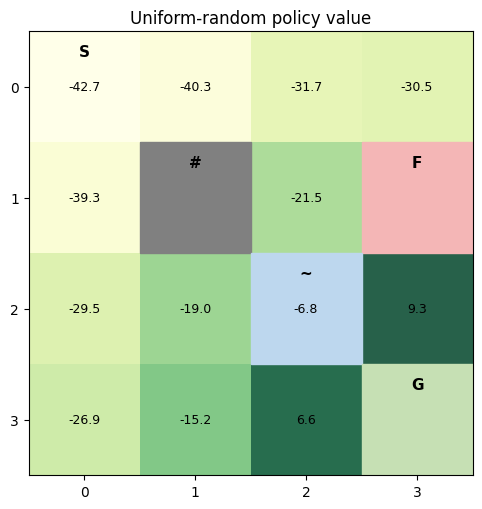

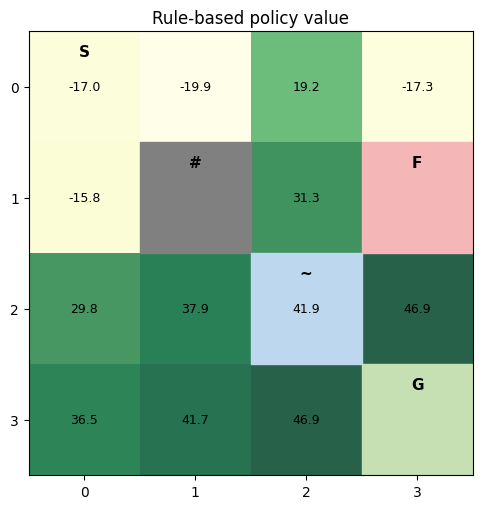

In [9]:
uniform_policy = np.full((n_states, n_actions), 1.0 / n_actions)
gamma = 0.95

V_uniform, sweeps_uniform, deltas_uniform = policy_evaluation(P, R, uniform_policy, gamma)
V_rule, sweeps_rule, deltas_rule = policy_evaluation(P, R, rule_policy, gamma)
start = state_index[(0, 0)]

print(f"Uniform random: V(start)={V_uniform[start]:.6f}, sweeps={sweeps_uniform}")
print(f"Rule-based:    V(start)={V_rule[start]:.6f}, sweeps={sweeps_rule}")
plot_grid(values=V_uniform, title="Uniform-random policy value")
plot_grid(values=V_rule, title="Rule-based policy value")


### Task 3: Verify Against the Exact Solution

Solve $V^\pi = (I - \gamma P_\pi)^{-1} r_\pi$ exactly with `np.linalg.solve`, and report the maximum absolute difference from your iterative solution for both policies. Plot the maximum change per sweep on a logarithmic y-axis.


Uniform max |iterative - exact|: 1.0012956032312559e-05
Rule max |iterative - exact|:    6.555063588820076e-06


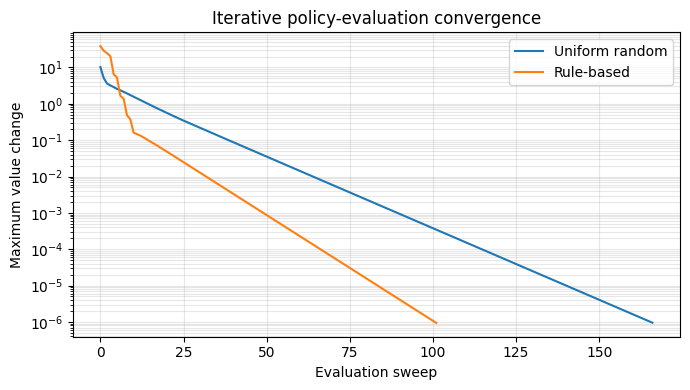

In [10]:
def exact_policy_value(P, R, policy, gamma):
    """Exact solution of the Bellman expectation equation via a linear solve."""
    n_states = P.shape[0]
    r_sa = np.sum(P * R, axis=2)
    r_pi = np.sum(policy * r_sa, axis=1)
    P_pi = np.einsum("sa,san->sn", policy, P)
    return np.linalg.solve(np.eye(n_states) - gamma * P_pi, r_pi)

V_uniform_exact = exact_policy_value(P, R, uniform_policy, gamma)
V_rule_exact = exact_policy_value(P, R, rule_policy, gamma)
print("Uniform max |iterative - exact|:", np.max(np.abs(V_uniform - V_uniform_exact)))
print("Rule max |iterative - exact|:   ", np.max(np.abs(V_rule - V_rule_exact)))

plt.figure(figsize=(7, 4))
plt.semilogy(deltas_uniform, label="Uniform random")
plt.semilogy(deltas_rule, label="Rule-based")
plt.xlabel("Evaluation sweep")
plt.ylabel("Maximum value change")
plt.title("Iterative policy-evaluation convergence")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Questions**

1. **Why can V^pi be computed without simulating a single episode?**

   The complete transition probabilities `P`, rewards `R`, policy, and discount factor are known. They define a finite system of Bellman expectation equations, so expectations over all possible next states can be calculated directly and the system can be solved by iteration or linear algebra.

2. **Under the rule-based policy, which states have the lowest values, and what causes this?**

   The lowest non-terminal values occur at **(0,1), (0,3), (0,0), and (1,0)**. At (0,1) and (1,0), the rule repeatedly aims into the shelf, so most intended moves are blocked and incur the extra bump penalty. At (0,3), it aims downward toward the forklift terminal. These effects also reduce the start value.

3. **Why does the random policy need more sweeps than the rule-based policy?**

   The random policy often wanders, bumps into boundaries/shelves, and takes longer to terminate. Rewards therefore propagate through longer effective trajectories, and its Bellman operator approaches the fixed point more slowly. The rule-based policy usually terminates sooner, so its values settle in fewer sweeps.

The terminal value remains exactly zero in both iterative evaluations.


---
## Part 3: Value Iteration and Policy Iteration  *(45 min)*

### Task 1: Value Iteration

Initialise $V = 0$ and iterate

$$V_{k+1}(s) = \max_a \sum_{s'} P(s'|s,a)\,[\,R(s,a,s') + \gamma V_k(s')\,]$$

until the maximum change is below $10^{-6}$.


Value Iteration converged in 35 sweeps, V*(start) = 25.561


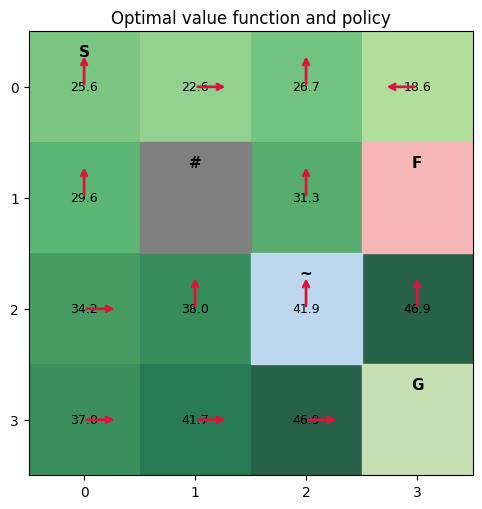

In [11]:
def value_iteration(P, R, gamma, theta=1e-6, max_sweeps=100_000):
    """Return optimal V, a greedy action-index policy, and sweep count."""
    n_states, n_actions = P.shape[0], P.shape[1]
    V = np.zeros(n_states)
    r_sa = np.sum(P * R, axis=2)

    for n_sweeps in range(1, max_sweeps + 1):
        Q = r_sa + gamma * (P @ V)
        V_new = Q.max(axis=1)
        delta = np.max(np.abs(V_new - V))
        V = V_new
        if delta < theta:
            break
    else:
        raise RuntimeError("value iteration did not converge")

    Q = r_sa + gamma * (P @ V)
    pi = Q.argmax(axis=1)
    return V, pi, n_sweeps


V_star, pi_star, n_sweeps_vi = value_iteration(P, R, gamma=0.95)
print(f"Value Iteration converged in {n_sweeps_vi} sweeps, V*(start) = {V_star[state_index[(0,0)]]:.3f}")
plot_grid(values=V_star, policy=pi_star, title="Optimal value function and policy")


### Task 2: Policy Iteration

In [12]:
def q_from_v(P, R, V, gamma):
    """Compute Q(s,a) from V. Shape: (n_states, n_actions)."""
    r_sa = np.sum(P * R, axis=2)
    return r_sa + gamma * (P @ V)


def policy_improvement(Q, policy_old, tol=1e-9):
    """Greedify Q while retaining the old action on near-ties."""
    best_values = Q.max(axis=1)
    new_actions = Q.argmax(axis=1)
    keep_old = Q[np.arange(Q.shape[0]), policy_old] >= best_values - tol
    new_actions[keep_old] = policy_old[keep_old]
    return new_actions


def policy_iteration(P, R, initial_policy, gamma, theta=1e-6, max_iters=200):
    """Policy Iteration with complete policy evaluation at each outer step."""
    n_states, n_actions = P.shape[:2]
    policy = initial_policy.copy()
    actions = policy.argmax(axis=1)
    history = []
    start_id = state_index[(0, 0)]
    nonterminal = np.arange(n_states) != terminal_id

    for _ in range(max_iters):
        V, eval_sweeps, _ = policy_evaluation(P, R, policy, gamma, theta)
        Q = q_from_v(P, R, V, gamma)
        new_actions = policy_improvement(Q, actions)
        n_changed = int(np.sum(new_actions[nonterminal] != actions[nonterminal]))
        history.append((eval_sweeps, n_changed, float(V[start_id])))
        actions = new_actions
        if n_changed == 0:
            break
        policy = np.zeros((n_states, n_actions))
        policy[np.arange(n_states), actions] = 1.0
    else:
        raise RuntimeError("policy iteration did not converge")

    # Return the value of the final stable policy.
    final_policy = np.zeros((n_states, n_actions))
    final_policy[np.arange(n_states), actions] = 1.0
    V, _, _ = policy_evaluation(P, R, final_policy, gamma, theta)
    return V, actions, history


V_pi_rand, pi_rand, hist_rand = policy_iteration(P, R, uniform_policy, gamma=0.95)
V_pi_rule, pi_rule, hist_rule = policy_iteration(P, R, rule_policy, gamma=0.95)

print("From random init:", hist_rand)
print("From rule-based init:", hist_rule)


From random init: [(167, 13, -42.709521738176996), (33, 5, 24.076895323447427), (36, 3, 24.670122643648206), (34, 1, 25.51609103375356), (35, 0, 25.56074649004302)]
From rule-based init: [(102, 4, -17.006763004768793), (34, 1, 24.873879494906518), (34, 1, 25.51609103375356), (35, 0, 25.56074649004302)]


### Task 3: Compare and Visualise

The following table is populated from the executed results (non-terminal states are used for policy agreement).

| Method | Outer iterations | Total sweeps | V*(start) | Agreement with VI (%) |
|---|---:|---:|---:|---:|
| Value Iteration | - | **35** | **25.561** | **100.00** |
| Policy Iteration (random init.) | **5** | **305** | **25.561** | **100.00** |
| Policy Iteration (rule-based init.) | **4** | **205** | **25.561** | **100.00** |


Method                                  Outer  Sweeps   V(start)   Agree %
Value Iteration                             -      35     25.561    100.00
Policy Iteration (random init.)             5     305     25.561    100.00
Policy Iteration (rule-based init.)         4     205     25.561    100.00


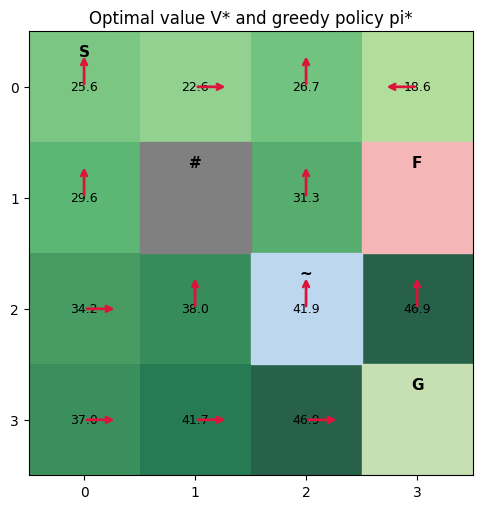

In [13]:
mask = np.arange(n_states) != terminal_id
rows = [
    ("Value Iteration", "-", n_sweeps_vi, V_star[start], 100.0),
    ("Policy Iteration (random init.)", len(hist_rand), sum(h[0] for h in hist_rand),
     V_pi_rand[start], 100 * np.mean(pi_rand[mask] == pi_star[mask])),
    ("Policy Iteration (rule-based init.)", len(hist_rule), sum(h[0] for h in hist_rule),
     V_pi_rule[start], 100 * np.mean(pi_rule[mask] == pi_star[mask])),
]
print(f"{'Method':38s} {'Outer':>6s} {'Sweeps':>7s} {'V(start)':>10s} {'Agree %':>9s}")
for name, outer, sweeps, value, agreement in rows:
    print(f"{name:38s} {str(outer):>6s} {sweeps:7d} {value:10.3f} {agreement:9.2f}")

plot_grid(values=V_star, policy=pi_star, title="Optimal value V* and greedy policy pi*")


**Questions**

1. **Why does Policy Iteration need few outer iterations but many total sweeps?**

   Each outer iteration performs a nearly exact policy evaluation, which can require many Bellman sweeps before the 1e-6 tolerance is reached. Once those accurate values are available, one greedy improvement can correct many state actions simultaneously, so only a few outer iterations are needed.

2. **Does the initial policy affect the final optimal policy or value function? Justify using your results.**

   No. Both initializations reached `V*(start) = 25.561` and 100% non-terminal action agreement with Value Iteration. The initialization affected computational effort: the random start used 305 evaluation sweeps, versus 205 from the rule-based start.

3. **In which states does pi* differ from the rule-based policy, and why is the rule-based action suboptimal there?**

   They differ at **(0,1), (0,3), (1,0), and (2,1)**. At (0,1) and (1,0), the rule aims into the shelf; at (0,3), it aims into the forklift. At (2,1), it heads onto the wet floor, while the optimal action moves down along the safer bottom route. Thus the rule ignores obstacles, terminal hazards, and state-dependent movement noise.


---
## Part 4: Sensitivity Analysis and Policy Benchmark  *(30 min)*

### Task 1: Sensitivity Analysis

Only one parameter group is changed from the baseline at a time. For Experiment B, `p_wet = p - 0.2`, except that both probabilities are 1.0 in the deterministic setting.

| Experiment | Setting | V*(start) | % actions changed |
|---|---|---:|---:|
| A | gamma = 0.5 | **-2.307** | **0.00** |
| A | gamma = 0.9 | **16.613** | **0.00** |
| A | gamma = 0.99 | **35.508** | **7.69** |
| B | 1.0 | **33.391** | **7.69** |
| B | 0.8 (baseline) | **25.561** | **0.00** |
| B | 0.6 | **12.615** | **15.38** |


In [14]:
def pct_actions_changed(pi_a, pi_b, terminal_id=terminal_id):
    """Percentage of non-terminal states where greedy actions differ."""
    mask = np.arange(len(pi_a)) != terminal_id
    return 100.0 * (pi_a[mask] != pi_b[mask]).mean()


sens_rows = []
for g in [0.5, 0.9, 0.99]:
    V_g, pi_g, sweeps_g = value_iteration(P, R, gamma=g)
    sens_rows.append(("A", f"gamma={g}", V_g[start], pct_actions_changed(pi_g, pi_star)))

for p_move in [1.0, 0.8, 0.6]:
    p_wet = 1.0 if p_move == 1.0 else p_move - 0.2
    P_b, R_b, idx_b, terminal_b = build_mdp(p=p_move, p_wet=p_wet)
    V_b, pi_b, sweeps_b = value_iteration(P_b, R_b, gamma=0.95)
    sens_rows.append(("B", f"p={p_move}, p_wet={p_wet}",
                      V_b[idx_b[(0, 0)]], pct_actions_changed(pi_b, pi_star, terminal_b)))

print(f"{'Exp.':4s} {'Setting':22s} {'V*(start)':>10s} {'Changed %':>10s}")
for exp, setting, value, changed in sens_rows:
    print(f"{exp:4s} {setting:22s} {value:10.3f} {changed:10.2f}")


Exp. Setting                 V*(start)  Changed %
A    gamma=0.5                  -2.307       0.00
A    gamma=0.9                  16.613       0.00
A    gamma=0.99                 35.508       7.69
B    p=1.0, p_wet=1.0           33.391       7.69
B    p=0.8, p_wet=0.6000000000000001     25.561       0.00
B    p=0.6, p_wet=0.39999999999999997     12.615      15.38


### Task 2: Benchmark the Three Policies

In [15]:
def deterministic_onehot(actions, n_actions=n_actions):
    policy = np.zeros((len(actions), n_actions))
    policy[np.arange(len(actions)), actions] = 1.0
    return policy


optimal_policy = deterministic_onehot(pi_star)
policies = {"Random": uniform_policy, "Rule-based": rule_policy, "Optimal pi*": optimal_policy}
benchmark = {}

for name, policy in policies.items():
    result = simulate(policy, n_episodes=500, max_steps=100, seed=42)
    outcomes = np.array(result["outcome"])
    exact_start = exact_policy_value(P, R, policy, gamma)[start]
    benchmark[name] = {
        "Exact V(start)": exact_start,
        "Mean return": result["return"].mean(),
        "Delivery rate": np.mean(outcomes == "goal"),
        "Forklift rate": np.mean(outcomes == "forklift"),
        "Timeout rate": np.mean(outcomes == "timeout"),
        "Blocked moves": result["blocked_moves"].mean(),
        "Episode length": result["length"].mean(),
    }

metrics = list(next(iter(benchmark.values())).keys())
print(f"{'Metric':23s}" + "".join(f"{name:>15s}" for name in policies))
for metric in metrics:
    values = [benchmark[name][metric] for name in policies]
    if "rate" in metric.lower():
        shown = [f"{100*v:.1f}%" for v in values]
    else:
        shown = [f"{v:.3f}" for v in values]
    print(f"{metric:23s}" + "".join(f"{v:>15s}" for v in shown))


Metric                          Random     Rule-based    Optimal pi*
Exact V(start)                 -42.710        -17.007         25.561
Mean return                    -43.276        -17.627         24.926
Delivery rate                    40.0%          97.8%          97.8%
Forklift rate                    57.4%           2.2%           2.2%
Timeout rate                      2.6%           0.0%           0.0%
Blocked moves                   12.908          9.658          0.678
Episode length                  32.744         18.758          7.726


| Metric | Random | Rule-based | Optimal pi* |
|---|---:|---:|---:|
| Exact V^pi(start) | **-42.710** | **-17.007** | **25.561** |
| Mean discounted return (simulated) | **-43.276** | **-17.627** | **24.926** |
| Delivery rate | **40.0%** | **97.8%** | **97.8%** |
| Forklift collision rate | **57.4%** | **2.2%** | **2.2%** |
| Timeout rate | **2.6%** | **0.0%** | **0.0%** |
| Blocked moves per episode | **12.908** | **9.658** | **0.678** |
| Mean episode length | **32.744** | **18.758** | **7.726** |

**Questions**

1. **How closely do the simulated returns match the exact values, and why do they differ at all?**

   The simulated means differ from the exact values by about **0.566** (random), **0.620** (rule-based), and **0.635** (optimal). Exact evaluation averages over every modeled transition, whereas 500 rollouts form a finite random sample. Rare slips, collisions, and different episode lengths create sampling variation; more episodes would normally reduce it.

2. **Which parameter, gamma or movement uncertainty, changes the optimal policy more? Explain the mechanism in one state where the action changes.**

   Movement uncertainty changes more actions: reducing accuracy to 0.6 changes **15.38%**, while the largest discount-factor change is **7.69%**. For example, at **(2,1)** the baseline policy moves `Down` to avoid the wet floor, but at accuracy 0.6 it moves `Right`; altered intended/slip probabilities change the relative risk of the wet route and surrounding outcomes. Discounting mainly changes when rewards matter, whereas uncertainty directly changes transition risk.

3. **Which failure mode dominates the rule-based policy, and how does pi* avoid it?**

   Blocked movement dominates the rule-based policy: it averages **9.658 blocked moves** per episode because it can repeatedly aim into the shelf or a boundary. The optimal policy changes the problematic actions near the shelf and wet floor, reducing blocked moves to **0.678** and shortening episodes from **18.758** to **7.726** steps. Both policies have a 97.8% delivery rate here, but the optimal route achieves much higher return by avoiding wasted, penalized steps.


---
## Part 5: Comparative Analysis  *(10 min)*

### Task 1: Compare the Two Approaches

| Feature | Simulation-based comparison (Lab 3) | Dynamic programming (Lab 4) |
|---|---|---|
| Knowledge of P and R required | No exact model required; an environment/simulator is enough | Yes; all transition probabilities and expected rewards must be available |
| Policy evaluation | Sample average from finitely many rollouts; noisy estimate | Bellman expectation equation; deterministic to a chosen tolerance or exact linear solve |
| Optimality guarantee | Comparing a few tested policies does not guarantee an optimum | Value/Policy Iteration converges to an optimal value and policy for this finite discounted MDP |
| Scalability with the number of states | Avoids storing a full transition tensor, but may need many episodes | Poor for large spaces because it stores/sweeps over all state-action-next-state combinations |
| Typical use | Unknown model, empirical benchmarking, or large environments | Small known models requiring exact planning and analysis |

### Task 2: Interpretation 

Exact dynamic programming represents a value for every state and repeatedly backs up every state-action pair. With an explicit transition model, a dense representation may contain a probability for every `(state, action, next state)` triple, so memory can grow on the order of the square of the state count and each sweep becomes expensive. Even sparse models become impractical when the state space is continuous or combinatorially large. Policy evaluation by a linear solve is also costly as the number of states grows.

When `P` and `R` are unknown, Bellman expectations cannot be calculated directly. The agent must interact with the environment and use sampled transitions and rewards. Monte Carlo methods estimate returns from complete episodes, while temporal-difference and Q-learning methods update estimates incrementally from experience. Function approximation can replace one table entry per state, allowing knowledge to generalize across similar states. The trade-off is sampling noise and weaker finite-sample guarantees, but these methods can operate without a complete model.


---
## Optional Extension (Bonus): Truncated Policy Iteration

Truncated Policy Iteration performs only a limited number of policy-evaluation sweeps before the next greedy improvement. The experiment below uses the uniform policy as the initial policy and stops as soon as

$$\lVert V - V^* \rVert_\infty < 10^{-4}.$$

| Evaluation sweeps per improvement | Total sweeps to tolerance | Outer iterations |
|---|---:|---:|
| $m=1$ | **28** | **28** |
| $m=5$ | **32** | **7** |
| Until convergence | **349** | **4** |

With $m=1$, the policy is made greedy with respect to the current values and then evaluated for one sweep. That update is
$V_{k+1}(s)=\max_a\sum_{s'}P(s'\mid s,a)[R+\gamma V_k(s')]$, exactly the Value Iteration backup. Larger $m$ values spend more work evaluating each intermediate policy; this reduces the number of policy improvements but does not necessarily reduce the total number of Bellman sweeps.


In [16]:

def truncated_policy_iteration(P, R, initial_policy, gamma, m, V_star,
                               tol=1e-4, eval_theta=1e-6, max_outer=10_000):
    """Modified Policy Iteration with at most m evaluation sweeps.

    Parameters
    ----------
    m : int or None
        Number of evaluation sweeps after each improvement. Use None for
        evaluation until convergence.

    Returns
    -------
    V, actions, total_sweeps, history
        Each history entry is (outer_iteration, sweeps_this_iteration,
        total_sweeps, infinity_norm_error).
    """
    n_states, n_actions = P.shape[:2]
    V = np.zeros(n_states)
    actions = initial_policy.argmax(axis=1)
    r_sa = np.sum(P * R, axis=2)
    total_sweeps = 0
    history = []

    for outer in range(1, max_outer + 1):
        # Improve first. For m=1, the following single evaluation sweep is
        # therefore exactly one Bellman optimality (Value Iteration) backup.
        Q = r_sa + gamma * (P @ V)
        actions = policy_improvement(Q, actions)
        policy = np.zeros((n_states, n_actions))
        policy[np.arange(n_states), actions] = 1.0
        r_pi = np.sum(policy * r_sa, axis=1)
        P_pi = np.einsum("sa,san->sn", policy, P)

        sweeps_this_outer = 0
        while True:
            V_new = r_pi + gamma * (P_pi @ V)
            delta = float(np.max(np.abs(V_new - V)))
            V = V_new
            sweeps_this_outer += 1
            total_sweeps += 1

            error = float(np.max(np.abs(V - V_star)))
            if error < tol:
                history.append((outer, sweeps_this_outer, total_sweeps, error))
                return V, actions, total_sweeps, history

            if m is not None and sweeps_this_outer >= m:
                break
            if m is None and delta < eval_theta:
                break

        history.append((outer, sweeps_this_outer, total_sweeps, error))

    raise RuntimeError("truncated policy iteration did not reach the requested tolerance")


bonus_results = {}
for label, m in [("m=1", 1), ("m=5", 5), ("until convergence", None)]:
    V_tpi, pi_tpi, total, history = truncated_policy_iteration(
        P, R, uniform_policy, gamma=0.95, m=m, V_star=V_star, tol=1e-4
    )
    bonus_results[label] = (total, len(history), history[-1][3])

print(f"{'Evaluation':20s} {'Total sweeps':>12s} {'Outer iters':>12s} {'Final error':>14s}")
for label, (total, outer, error) in bonus_results.items():
    print(f"{label:20s} {total:12d} {outer:12d} {error:14.6g}")


Evaluation           Total sweeps  Outer iters    Final error
m=1                            28           28    6.25036e-05
m=5                            32            7    6.29217e-05
until convergence             349            4     5.8782e-05
